In [4]:
import pandas as pd 
import matplotlib.pyplot as plt
import numpy as np 
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from seaborn import heatmap
import seaborn as sns
import re
from collections import Counter

<div markdown="1" style="background-color: rgba(248, 249, 250, 0.85); color: #1f2328; padding: 32px 36px; border-radius: 14px; border: 1px solid rgba(208, 215, 222, 0.7); box-shadow: 0 8px 24px rgba(140, 149, 159, 0.15); font-family: -apple-system, BlinkMacSystemFont, 'Segoe UI', Roboto, Helvetica, Arial, sans-serif; line-height: 1.65;">

# Multinomial Naive Bayes — Theory and Mathematical Foundations

## 1. Introduction to Naive Bayes

Naive Bayes is a family of supervised machine learning algorithms based on **Bayes' theorem**.

It is commonly used for classification problems, particularly text classification tasks such as:

- Email spam detection
- Sentiment analysis
- Document classification
- News categorization

The central idea is to calculate the probability that an observation belongs to each possible class, given the features observed in that observation.

For example, in SMS spam detection, we want to determine whether a message belongs to one of two classes:

- `ham`: a normal message
- `spam`: an unwanted or promotional message

Given a message such as:

> "Congratulations! You have won a free prize."

Our goal is to estimate:

- The probability that the message is spam.
- The probability that the message is ham.

We then assign the message to the class with the highest probability.

---

## 2. Probability Foundations

Before understanding Naive Bayes, we need to understand a few probability concepts.

### 2.1 Prior Probability

A prior probability represents the probability of an event before considering new evidence.

For example, suppose our training dataset contains:

- 800 ham messages
- 200 spam messages

There are 1000 messages in total.

The prior probabilities are:

$$
P(\text{ham}) = \frac{800}{1000} = 0.8
$$

$$
P(\text{spam}) = \frac{200}{1000} = 0.2
$$

This tells us that, before examining a message's words, we expect 80% of messages to be ham and 20% to be spam.

In classification, the prior probability of a class is:

$$
P(C) = \frac{\text{Number of observations in class } C}
{\text{Total number of observations}}
$$

### 2.2 Conditional Probability

Conditional probability describes the probability of an event occurring given that another event has already occurred.

It is written as:

$$
P(A \mid B) = \frac{P(A \cap B)}{P(B)}
$$

Where:

- $P(A \mid B)$: Probability of event A given that B has occurred.
- $P(A \cap B)$: Probability that both A and B occur.
- $P(B)$: Probability of event B.

For example:

$$
P(\text{spam} \mid \text{message contains "free"})
$$

This represents the probability that a message is spam, given that it contains the word "free".

Notice that this is different from:

$$
P(\text{free} \mid \text{spam})
$$

The latter represents the probability that a spam message contains the word "free".

The distinction between these two probabilities is fundamental to Naive Bayes.

---

## 3. Bayes' Theorem

Bayes' theorem allows us to reverse conditional probabilities.

It calculates the probability of a hypothesis given some observed evidence.

$$
P(A \mid B) =
\frac{P(B \mid A)P(A)}{P(B)}
$$

In classification, we can express this as:

$$
P(C \mid X) =
\frac{P(X \mid C)P(C)}{P(X)}
$$

Where:

- $P(C \mid X)$: Posterior probability — probability of class C given the observation X.
- $P(X \mid C)$: Likelihood — probability of observing X given class C.
- $P(C)$: Prior probability of class C.
- $P(X)$: Evidence — overall probability of observing X.

### 3.1 Applying Bayes' Theorem to Spam Detection

Suppose we want to calculate the probability that a message is spam, given that it contains the word "free".

We know:

$$
P(\text{spam}) = 0.2
$$

$$
P(\text{free} \mid \text{spam}) = 0.5
$$

$$
P(\text{free}) = 0.15
$$

Using Bayes' theorem:

$$
P(\text{spam} \mid \text{free})
=
\frac{
P(\text{free} \mid \text{spam})
P(\text{spam})
}{
P(\text{free})
}
$$

$$
=
\frac{0.5 \times 0.2}{0.15}
\approx 0.667
$$

Therefore, given that the message contains "free", the probability of it being spam is approximately 66.7%.

---

## 4. The Naive Assumption

In real-world text classification, a message usually contains multiple words.

For example:

> "Congratulations you have won a free prize"

Let the words in the message be:

$$
X = (w_1, w_2, w_3, \ldots, w_n)
$$

We want to calculate:

$$
P(C \mid w_1, w_2, \ldots, w_n)
$$

Using Bayes' theorem:

$$
P(C \mid X) =
\frac{P(X \mid C)P(C)}{P(X)}
$$

The difficult part is calculating:

$$
P(X \mid C)
$$

This is the probability of observing the entire message given a particular class.

Naive Bayes makes a simplifying assumption:

**All features are conditionally independent given the class.**

In other words, once we know that a message belongs to a particular class, the occurrence of one word is assumed not to affect the probability of another word occurring.

Under this assumption:

$$
P(X \mid C)
=
P(w_1 \mid C)
P(w_2 \mid C)
\cdots
P(w_n \mid C)
$$

Or, more compactly:

$$
P(X \mid C) =
\prod_{i=1}^{n} P(w_i \mid C)
$$

This is the reason for the word "Naive" in Naive Bayes.

In natural language, words are obviously not truly independent. For example, "New" and "York" are related. Nevertheless, this assumption often works surprisingly well for text classification.

---

## 5. Multinomial Naive Bayes

There are different variants of Naive Bayes, including:

- Gaussian Naive Bayes
- Bernoulli Naive Bayes
- Multinomial Naive Bayes

For our SMS classification project, we use **Multinomial Naive Bayes**.

Multinomial Naive Bayes is particularly suitable for discrete features such as word frequencies.

Unlike a simple binary representation, it takes into account how many times a word occurs in a document.

For example:

Message A:

> "free free free prize"

Message B:

> "free prize"

The word "free" occurs three times in Message A but only once in Message B.

Multinomial Naive Bayes considers these different frequencies.

### 5.1 Vocabulary

The vocabulary is the collection of all unique words observed in the training dataset.

For example, consider these training messages:

- "free prize now"
- "win free money"
- "hello there"

The vocabulary is:

$$
V = \{\text{free, prize, now, win, money, hello, there}\}
$$

The size of the vocabulary is:

$$
|V| = 7
$$

Every word in a message is considered in relation to this vocabulary.

### 5.2 Word Likelihood

For each class, we estimate the probability of observing each word.

The likelihood of a word $w$ given class $C$ is:

$$
P(w \mid C) =
\frac{\text{Count}(w,C)}
{\text{Total number of word occurrences in } C}
$$

For example, suppose all spam messages combined contain 1000 word occurrences, and the word "free" appears 100 times.

Then:

$$
P(\text{free} \mid \text{spam})
=
\frac{100}{1000}
= 0.1
$$

This means that 10% of all word occurrences in spam messages are the word "free".

We calculate these probabilities separately for every word and every class.

---

## 6. Laplace Smoothing

### 6.1 The Zero-Probability Problem

Suppose the word "meeting" never appears in any spam message in our training dataset.

Then:

$$
P(\text{meeting} \mid \text{spam}) = 0
$$

Now consider a message:

> "free meeting prize"

According to the Naive Bayes assumption:

$$
P(X \mid \text{spam}) =
P(\text{free} \mid \text{spam})
P(\text{meeting} \mid \text{spam})
P(\text{prize} \mid \text{spam})
$$

Because one of the probabilities is zero:

$$
P(X \mid \text{spam}) = 0
$$

This is problematic. A single word that was never observed in a class makes the probability of the entire message zero.

### 6.2 Additive (Laplace) Smoothing

To solve this problem, we add a small positive value to every word count.

This technique is called **Laplace smoothing**, also known as additive smoothing.

The smoothed likelihood is:

$$
P(w \mid C) =
\frac{\text{Count}(w,C) + \alpha}
{N_C + \alpha |V|}
$$

Where:

- $\text{Count}(w,C)$: Number of occurrences of word $w$ in class C.
- $N_C$: Total number of word occurrences in class C.
- $|V|$: Number of unique words in the vocabulary.
- $\alpha$: Smoothing parameter.

The most common choice is:

$$
\alpha = 1
$$

This is called Laplace smoothing.

When $\alpha = 1$, we add one to every word count.

### 6.3 Example

Suppose:

- The vocabulary contains 5 unique words.
- The word "meeting" occurs 0 times in spam messages.
- Spam messages contain 100 word occurrences in total.
- We use $\alpha = 1$.

Without smoothing:

$$
P(\text{meeting} \mid \text{spam}) =
\frac{0}{100} = 0
$$

With Laplace smoothing:

$$
P(\text{meeting} \mid \text{spam}) =
\frac{0+1}{100+(1 \times 5)}
$$

$$
= \frac{1}{105}
\approx 0.00952
$$

Now the probability is small, but it is no longer zero.

### 6.4 Why Do We Add $\alpha |V|$ to the Denominator?

We add $\alpha$ to the count of every word in the vocabulary.

Since the vocabulary contains $|V|$ unique words, the total additional count is:

$$
\underbrace{\alpha + \alpha + \cdots + \alpha}_{|V|\text{ times}}
=
\alpha |V|
$$

Therefore, the denominator must also increase by $\alpha |V|$ to ensure that all word probabilities still sum to one.

$$
\sum_{w \in V} P(w \mid C) = 1
$$

---

## 7. Calculating the Posterior Probability

Now we can combine the prior and likelihood calculations.

For a message containing words:

$$
X = (w_1,w_2,\ldots,w_n)
$$

The posterior probability of a class is proportional to:

$$
P(C \mid X)
\propto
P(C) \prod_{i=1}^{n} P(w_i \mid C)
$$

The proportionality symbol is used because the denominator $P(X)$ is the same for every class when classifying the same message.

For classification, we therefore compare:

$$
\hat{C}
=
\arg\max_C
\left[
P(C)\prod_{i=1}^{n}P(w_i \mid C)
\right]
$$

The $\arg\max$ operation returns the class that produces the highest value.

For example:

$$
Score(\text{ham}) =
P(\text{ham})
\prod_{i=1}^{n}P(w_i \mid \text{ham})
$$

$$
Score(\text{spam}) =
P(\text{spam})
\prod_{i=1}^{n}P(w_i \mid \text{spam})
$$

We predict whichever class has the higher score.

---

## 8. Why Do We Use Logarithms?

There is a numerical problem with multiplying many small probabilities.

For example:

$$
0.01 \times 0.02 \times 0.03 \times \cdots
$$

As the number of words increases, the product can become extremely small.

Eventually, a computer may represent the result as zero due to floating-point underflow.

To avoid this problem, we use logarithms.

### 8.1 Logarithm Properties

One important logarithm property is:

$$
\log(a \times b) = \log(a) + \log(b)
$$

Therefore:

$$
\log\left(
P(C)\prod_{i=1}^{n}P(w_i \mid C)
\right)
$$

becomes:

$$
\log P(C) +
\sum_{i=1}^{n}\log P(w_i \mid C)
$$

Our final log-score is:

$$
Score(C) =
\log P(C) +
\sum_{i=1}^{n}\log P(w_i \mid C)
$$

Instead of multiplying many small numbers, we add their logarithms.

Since the logarithm is a strictly increasing function, it preserves the ordering of positive values.

Therefore, the class with the highest original score also has the highest log-score.

**Important:** These log-scores are not probabilities. They are useful numerical scores for comparing classes.

---

## 9. Converting Scores into Probabilities: Activation Functions

Our model produces one log-score for each class.

For example:

$$
Scores =
\begin{bmatrix}
-12.5 & -8.2
\end{bmatrix}
$$

These scores are not probabilities because:

- They can be negative.
- They do not necessarily lie between 0 and 1.
- They do not necessarily sum to 1.

If we want a probability distribution over the classes, we need to normalize the scores.

There are several possible transformations.

### 9.1 Softmax

Softmax converts a vector of real-valued scores into a probability distribution.

For class $i$:

$$
Softmax(z_i) =
\frac{e^{z_i}}{\sum_{j=1}^{K}e^{z_j}}
$$

Where:

- $z_i$: Score of class i.
- $K$: Number of classes.
- $e$: Euler's number.

The resulting values satisfy:

$$
0 < Softmax(z_i) < 1
$$

And:

$$
\sum_{i=1}^{K}Softmax(z_i) = 1
$$

For example:

$$
Scores = [2,1]
$$

After applying softmax:

$$
Softmax([2,1])
\approx [0.731,0.269]
$$

The model assigns approximately:

- 73.1% probability to the first class.
- 26.9% probability to the second class.

#### Numerical Stability

To avoid numerical overflow when calculating exponentials, we subtract the maximum score before applying softmax:

$$
Softmax(z_i) =
\frac{e^{z_i-M}}{\sum_{j=1}^{K}e^{z_j-M}}
$$

Where:

$$
M = \max(z_1,z_2,\ldots,z_K)
$$

This does not change the resulting probabilities.

### 9.2 Sigmoid

The sigmoid function transforms an individual real-valued score into a value between zero and one.

$$
\sigma(z) =
\frac{1}{1+e^{-z}}
$$

For example:

$$
\sigma(2) \approx 0.881
$$

$$
\sigma(-2) \approx 0.119
$$

Unlike softmax, sigmoid does not normalize multiple class scores together.

For example:

$$
Sigmoid([2,1])
\approx [0.881,0.731]
$$

These values do not sum to one.

Sigmoid is commonly used for binary classification when modeling a single probability, or for multi-label classification where classes are not mutually exclusive.

For our mutually exclusive ham/spam classes, sigmoid applied independently to both class scores does not produce a valid posterior probability distribution.

### 9.3 Log-Softmax

Log-softmax calculates the logarithm of softmax probabilities directly.

$$
LogSoftmax(z_i) =
z_i - \log\left(\sum_{j=1}^{K}e^{z_j}\right)
$$

For numerical stability, we can subtract the maximum score:

$$
LogSoftmax(z_i) =
(z_i-M) -
\log\left(\sum_{j=1}^{K}e^{z_j-M}\right)
$$

The output consists of log-probabilities rather than ordinary probabilities.

For example, if softmax produces:

$$
[0.731,0.269]
$$

Log-softmax produces approximately:

$$
[-0.313,-1.313]
$$

Exponentiating the log-softmax values gives us the original probabilities.

Log-softmax is useful when we want normalized log-probabilities without unnecessarily converting back and forth between probabilities and logarithms.

### 9.4 Comparison

| Function | Output range | Outputs sum to 1? | Main use |
|---|---|---|---|
| Softmax | (0, 1) | Yes | Multiclass probabilities |
| Sigmoid | (0, 1) | No | Independent binary probabilities |
| Log-softmax | (-∞, 0) | After exponentiation | Multiclass log-probabilities |

**For our Multinomial Naive Bayes classifier, softmax is the appropriate default when we want normalized class probabilities.**

Note that applying softmax to our Naive Bayes log-scores recovers the normalized posterior probabilities, because the common evidence term cancels during normalization.

---

## 10. Unknown Words (Out-of-Vocabulary Words)

During prediction, a message may contain words that were never observed in the training dataset.

These words are called out-of-vocabulary (OOV) words.

For example:

Training vocabulary:

$$
V = \{\text{free, money, hello, prize}\}
$$

New message:

> "free amazing prize"

The word "amazing" does not belong to our training vocabulary.

A common approach in Multinomial Naive Bayes is to ignore words that are not in the training vocabulary.

Therefore, the model calculates the score using:

$$
Score(C) =
\log P(C) +
\sum_{\substack{w \in X \\ w \in V}}
\log P(w \mid C)
$$

We must use the vocabulary learned from the training data. We should not add words from the test data to the vocabulary, because that would introduce information from the test set into the training process.

---

## 11. Complete Classification Process

The complete Multinomial Naive Bayes classification process can be divided into two main stages.

### Stage 1: Training

1. Separate the training messages according to their classes.
2. Build a vocabulary containing all unique words in the training dataset.
3. Count the occurrences of each word in each class.
4. Calculate the prior probability of every class.
5. Calculate the smoothed likelihood of every word in every class using Laplace smoothing.
6. Store the learned probabilities for future predictions.

### Stage 2: Prediction

For each new message:

1. Tokenize the message.
2. Identify the words that belong to the training vocabulary.
3. Calculate the log-score for each class.
4. Apply softmax to convert the scores into normalized posterior probabilities.
5. Select the class with the highest probability.

Mathematically:

$$
\boxed{
\hat{C} =
\arg\max_C
\left[
\log P(C) +
\sum_{w \in X \cap V}
\log P(w \mid C)
\right]
}
$$

---

## 12. Limitations and Assumptions

Although Naive Bayes is computationally efficient and often performs well, it has several limitations.

**1. Conditional independence assumption**

It assumes that features are conditionally independent given the class. This is often unrealistic for natural language.

**2. Bag-of-words representation**

Multinomial Naive Bayes generally considers word frequencies rather than word order.

For example:

- "The dog chased the cat."
- "The cat chased the dog."

These messages contain the same word frequencies, so a basic bag-of-words model cannot distinguish their word order.

**3. Dependence on vocabulary**

Words not present in the training vocabulary are generally ignored.

**4. Probability estimates**

The model's probability estimates may not always be well calibrated, even when its classification accuracy is good.

**5. Smoothing parameter**

The choice of $\alpha$ affects the likelihood estimates. A value of 1 is a common starting point, but other values may perform better.

---

## 13. Summary of Important Equations

| Concept | Equation |
|---|---|
| Bayes' theorem | $P(C \mid X)=\frac{P(X \mid C)P(C)}{P(X)}$ |
| Prior probability | $P(C)=\frac{N_C}{N}$ |
| Naive independence | $P(X \mid C)=\prod_{i=1}^{n}P(w_i \mid C)$ |
| Laplace smoothing | $P(w \mid C)=\frac{Count(w,C)+\alpha}{N_C+\alpha|V|}$ |
| Log-score | $\log P(C)+\sum_{i=1}^{n}\log P(w_i \mid C)$ |
| Softmax | $\frac{e^{z_i}}{\sum_j e^{z_j}}$ |
| Sigmoid | $\frac{1}{1+e^{-z}}$ |
| Log-softmax | $z_i-\log(\sum_j e^{z_j})$ |

**Final objective:** Given a new message, estimate its posterior probability for every class and assign it to the class with the highest probability.

</div>

In [8]:
df = pd.DataFrame(pd.read_csv("./spam.csv"))


df.columns = ['category', 'message']
df = df.dropna(subset=['category', 'message'])

df['category'] = df['category'].str.lower().str.strip()

df = df[df['category'].isin(['ham', 'spam'])].copy()

def clean_text(text):

    text = str(text).lower()
    text = re.sub(r'https?://\S+|www\.\S+', ' URLTOKEN ', text)

    text = re.sub(
        r'\b[\w.+-]+@[\w.-]+\.[a-z]{2,}\b',
        ' EMAILTOKEN ',
        text
    )
    text = re.sub(
        r'(?<!\w)\+?\d[\d\s().-]{7,}\d(?!\w)',
        ' PHONETOKEN ',
        text
    )

    return text

df['clean_message'] = df['message'].apply(clean_text)

def tokenize(text):
    return re.findall(r"[a-z]+(?:'[a-z]+)?|\d+", text)

df['tokens'] = df['clean_message'].apply(tokenize)

df['label'] = df['category'].map({
    'ham': 0,
    'spam': 1
}).astype(int)

df.head()

,category,message,clean_message,tokens,label
0,ham,"Go until jurong point, crazy.. Available only ...","go until jurong point, crazy.. available only ...","[go, until, jurong, point, crazy, available, o...",0
1,ham,Ok lar... Joking wif u oni...,ok lar... joking wif u oni...,"[ok, lar, joking, wif, u, oni]",0
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,free entry in 2 a wkly comp to win fa cup fina...,"[free, entry, in, 2, a, wkly, comp, to, win, f...",1
3,ham,U dun say so early hor... U c already then say...,u dun say so early hor... u c already then say...,"[u, dun, say, so, early, hor, u, c, already, t...",0
4,ham,"Nah I don't think he goes to usf, he lives aro...","nah i don't think he goes to usf, he lives aro...","[nah, i, don't, think, he, goes, to, usf, he, ...",0


In [46]:
X = np.array(df["tokens"].copy())
y = df["label"].copy()

X_train, X_tmp, y_train, y_tmp = train_test_split(X, y, train_size=0.7, random_state=42)
X_valid, X_test, y_valid, y_test = train_test_split(X_tmp, y_tmp, test_size=0.5, random_state=42)


In [47]:

class MultinomialNaiveBayes:

    def __init__(self, alpha=1, activation="softmax"):
        self.alpha = alpha

        activations = {
            "softmax": self.softmax,
            "sigmoid": self.sigmoid,
            "log_softmax": self.log_softmax
        }

        if activation not in activations:
            raise ValueError("Unknown activation function")

        self.activation = activations[activation]

        self.classes = None
        self.word_counts = None
        self.total_nmessages = None
        self.vocab = None
        self.class_probs = None
        self.vocab_size = None
        self.likelihoods = None

    def fit(self, X_train, y_train):

        self.classes = np.unique(y_train)
        self.total_nmessages = X_train.shape[0]

        self.word_counts = {}
        self.vocab = []
        self.vocab_size = 0

        self.likelihoods = {c: {} for c in self.classes}

        value_counts = y_train.value_counts()

        self.class_probs = {
            c: value_counts[c] / self.total_nmessages
            for c in self.classes
        }

        for c in self.classes:

            class_messages = X_train[y_train == c]
            class_words = np.concatenate(class_messages).tolist()

            self.vocab.extend(class_words)

            class_word_counts = Counter(class_words)
            self.word_counts[c] = class_word_counts

        self.vocab = list(dict.fromkeys(self.vocab))
        self.vocab_size = len(self.vocab)

        for c in self.classes:

            for w in self.vocab:

                word_likelihood = (
                    (self.word_counts[c][w] + self.alpha) /
                    (sum(self.word_counts[c].values())
                     + self.alpha * self.vocab_size)
                )

                self.likelihoods[c][w] = word_likelihood

        return self

    def predict_message(self, message_tokens):

        log_scores = {}

        for c in self.classes:

            log_likelihoods = np.array([
                np.log(self.likelihoods[c][w])
                for w in message_tokens
                if w in self.vocab
            ])

            log_scores[c] = (
                np.log(self.class_probs[c])
                + np.sum(log_likelihoods)
            )

        scores = np.array([
            log_scores[c] for c in self.classes
        ])

        probabilities = self.activation(scores)

        predicted_class = self.classes[np.argmax(probabilities)]

        return probabilities, predicted_class

    def predict(self, X_test):

        results = [
            self.predict_message(message)
            for message in X_test
        ]

        probabilities = np.array([r[0] for r in results])
        predictions = np.array([r[1] for r in results])

        return probabilities, predictions

    def softmax(self, scores):

        exp_scores = np.exp(scores - np.max(scores))
        return exp_scores / np.sum(exp_scores)

    def sigmoid(self, scores):
        """Suitable for binary classification with one score per class
        only as independent outputs, not normalized multiclass probabilities."""
        return 1 / (1 + np.exp(-np.clip(scores, -500, 500)))

    def log_softmax(self, scores):

        shifted = scores - np.max(scores)
        return shifted - np.log(np.sum(np.exp(shifted)))


In [51]:
model = MultinomialNaiveBayes(alpha=2, activation="sigmoid")
model.fit(X_train, y_train)

test Accuracy: 98.44%
              precision    recall  f1-score   support

           0       0.99      0.99      0.99       729
           1       0.92      0.96      0.94       107

    accuracy                           0.98       836
   macro avg       0.96      0.98      0.97       836
weighted avg       0.98      0.98      0.98       836



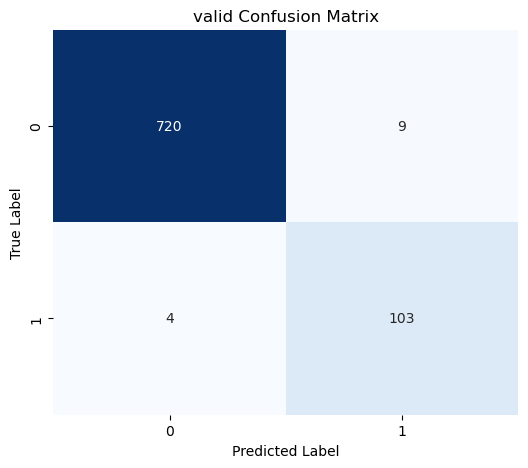

In [56]:


_, y_pred_valid = model.predict(X_valid)
cm_valid = confusion_matrix(y_pred_valid, y_valid)

accuracy = accuracy_score(y_pred_valid, y_valid)
print(f"test Accuracy: {accuracy * 100:.2f}%")
cr_valid = classification_report(y_pred_valid, y_valid)
print(cr_valid)

plt.figure(figsize=(6, 5))
sns.heatmap(cm_valid, annot=True, fmt="d", cmap="Blues", cbar=False,
            xticklabels=model.classes, yticklabels=model.classes)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("valid Confusion Matrix")
plt.show()


test Accuracy: 98.68%
              precision    recall  f1-score   support

           0       0.99      0.99      0.99       727
           1       0.94      0.96      0.95       109

    accuracy                           0.99       836
   macro avg       0.97      0.98      0.97       836
weighted avg       0.99      0.99      0.99       836



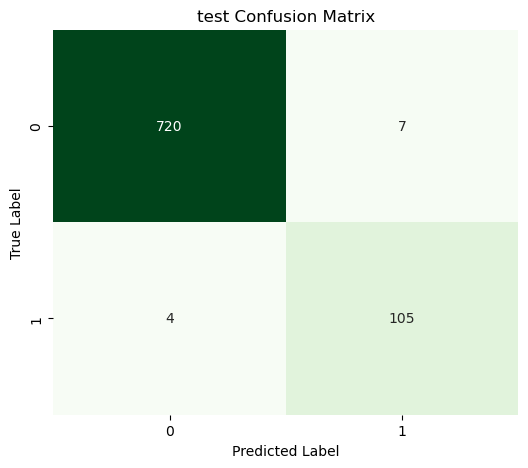

In [57]:

_, y_pred_test = model.predict(X_test)
cm_test = confusion_matrix(y_pred_test, y_test)

accuracy = accuracy_score(y_pred_test, y_test)
print(f"test Accuracy: {accuracy * 100:.2f}%")

cr_test = classification_report(y_pred_test, y_test)
print(cr_test)

plt.figure(figsize=(6, 5))
sns.heatmap(cm_test, annot=True, fmt="d", cmap="Greens", cbar=False,
            xticklabels=model.classes, yticklabels=model.classes)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("test Confusion Matrix")
plt.show()

In [58]:
!jupyter nbconvert --to pdf "Naive_Bayes_from_scratch.ipynb"

[NbConvertApp] Converting notebook Naive_Bayes_from_scratch.ipynb to pdf
[NbConvertApp] Support files will be in Naive_Bayes_from_scratch_files\
[NbConvertApp] Making directory .\Naive_Bayes_from_scratch_files
[NbConvertApp] Writing 67902 bytes to notebook.tex
[NbConvertApp] Building PDF
[NbConvertApp] Running xelatex 3 times: ['xelatex', 'notebook.tex', '-quiet']
[NbConvertApp] Running bibtex 1 time: ['bibtex', 'notebook']
[NbConvertApp] WARNING | b had problems, most likely because there were no citations
[NbConvertApp] PDF successfully created
[NbConvertApp] Writing 125929 bytes to Naive_Bayes_from_scratch.pdf
